<a href="https://colab.research.google.com/github/goldedan7/robot-dynamics/blob/main/P4_PID%20on%20the%20inverted%20pendulum/P4_PID_Control.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Key Concept
# Error = Target - theta
#Torque = Kp x Error

In [2]:
import numpy as np                          # numerical arrays & maths
import matplotlib.pyplot as plt             # plotting
from scipy.integrate import solve_ivp       # ODE solver

print("✓ Libraries ready")


✓ Libraries ready


In [3]:
g = 9.81  # gravity force (m/s^2)
L = 1.0   # Length of Pendulum (m)

print(f"✓ g: {g} m/s^2, L: {L} m")

✓ g: 9.81 m/s^2, L: 1.0 m


In [4]:
# Controller + dynamics combined
def pendulum_with_P_control(t, state, target, Kp):
  # state = [theta, omega]; t is required by solve_ivp but is not used
    theta, omega = state

    error = target - theta      # how far we are from where we want to be
    torque = Kp * error         # push proportionally to that error

    dtheta = omega
    # gravity term (same as P1) + our controller's torque added directly
    domega = -(g / L) * np.sin(theta) + torque

    return [dtheta, domega]


Kp=   5  (Kp > g/L? False)  last-2s swing = 146.35 deg
Kp=  15  (Kp > g/L? True)  last-2s swing =  20.00 deg
Kp=  30  (Kp > g/L? True)  last-2s swing =  20.00 deg
Kp=  50  (Kp > g/L? True)  last-2s swing =  20.00 deg
Kp= 100  (Kp > g/L? True)  last-2s swing =  20.00 deg


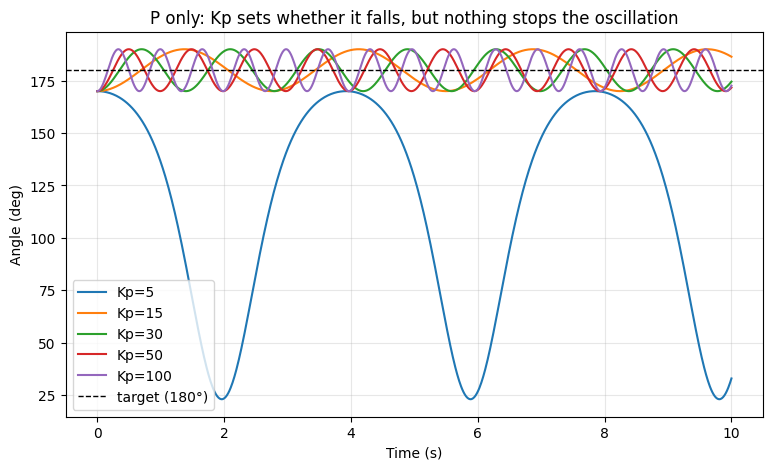

In [5]:
target = np.radians(180)          # hold the pendulum upside down
initial = [np.radians(170), 0.0]  # start 10 deg away, at rest
t_eval = np.linspace(0, 10, 1000)

plt.figure(figsize=(9, 5))

for Kp_test in [5, 15, 30, 50, 100]:
    sol = solve_ivp(pendulum_with_P_control, (0, 10), initial, t_eval=t_eval,
                    args=(target, Kp_test), rtol=1e-10, atol=1e-12)
    theta = sol.y[0]

    # swing amplitude over the last 2 s (last 200 of 1000 points)
    tail = theta[-200:]
    amp = np.degrees(tail.max() - tail.min())
    print(f"Kp={Kp_test:4.0f}  (Kp > g/L? {Kp_test > g/L})  last-2s swing = {amp:6.2f} deg")

    plt.plot(sol.t, np.degrees(theta), label=f'Kp={Kp_test}')

plt.axhline(180, color='k', linestyle='--', linewidth=1, label='target (180°)')
plt.xlabel('Time (s)'); plt.ylabel('Angle (deg)')
plt.title('P only: Kp sets whether it falls, but nothing stops the oscillation')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [6]:
for Kp_test in [0, 5, 15, 30, 50, 100]:
    sol_test = solve_ivp(pendulum_with_P_control, (0,10), initial, t_eval=t_eval,
                          args=(target, Kp_test), rtol=1e-10, atol=1e-12)
    theta_test = sol_test.y[0]

    # looking at just the last 2 seconds (last 200 points out of 1000)
    tail = theta_test[-200:]
    amp = np.degrees(tail.max() - tail.min())
    print(f"Kp={Kp_test:4.0f} -> last-2s swing amplitude = {amp:6.2f} deg")

Kp=   0 -> last-2s swing amplitude = 309.46 deg
Kp=   5 -> last-2s swing amplitude = 146.35 deg
Kp=  15 -> last-2s swing amplitude =  20.00 deg
Kp=  30 -> last-2s swing amplitude =  20.00 deg
Kp=  50 -> last-2s swing amplitude =  20.00 deg
Kp= 100 -> last-2s swing amplitude =  20.00 deg


In [7]:
def pendulum_with_PD_control(t, state, target, Kp, Kd, disturbance=0.0):
    theta, omega = state

    error = target - theta
    d_error = -omega            # d(error)/dt = -d(theta)/dt = -omega

    torque = Kp * error + Kd * d_error
    dtheta = omega
    domega = -(g / L) * np.sin(theta) + torque + disturbance
    return [dtheta, domega]

Kd=  0  last-3s amplitude = 19.9998 deg
Kd=  2  last-3s amplitude =  0.0001 deg
Kd=  5  last-3s amplitude =  0.0000 deg
Kd= 10  last-3s amplitude =  0.0000 deg
Kd= 20  last-3s amplitude =  0.0000 deg


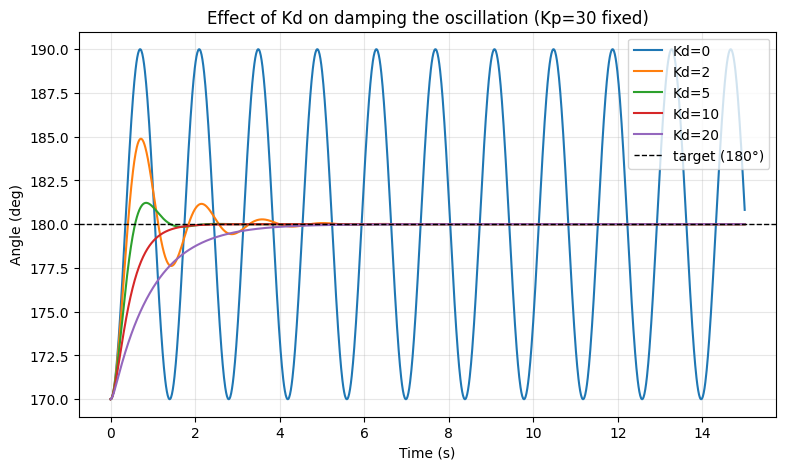

In [8]:
target = np.radians(180)
initial = [np.radians(170), 0.0]
t_eval = np.linspace(0, 15, 1500)
Kp_fixed = 30

plt.figure(figsize=(9, 5))

for Kd in [0, 2, 5, 10, 20]:
    sol = solve_ivp(pendulum_with_PD_control, (0,15), initial, t_eval=t_eval,
                     args=(target, Kp_fixed, Kd), rtol=1e-10, atol=1e-12)
    theta = sol.y[0]

    tail = theta[-300:]
    amp = np.degrees(tail.max() - tail.min())
    print(f"Kd={Kd:3.0f}  last-3s amplitude = {amp:7.4f} deg")

    plt.plot(sol.t, np.degrees(theta), label=f'Kd={Kd}')

plt.axhline(180, color='k', linestyle='--', linewidth=1, label='target (180°)')
plt.xlabel('Time (s)'); plt.ylabel('Angle (deg)')
plt.title(f'Effect of Kd on damping the oscillation (Kp={Kp_fixed} fixed)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
def pendulum_with_PD_control_disturbed(t, state, target, Kp, Kd, disturbance): #external torque
    theta, omega = state
    error = target - theta
    d_error = -omega
    torque = Kp*error + Kd*d_error

    dtheta = omega
    # constant disturbance torque added -- e.g. unmodeled friction/bias
    domega = -(g/L)*np.sin(theta) + torque + disturbance

    return [dtheta, domega]

In [10]:
target = np.radians(180)
initial = [np.radians(170), 0.0]
t_eval = np.linspace(0, 20, 2000)
Kp, Kd, disturbance = 30, 10, 2.0   # A constant disturbance torque

sol = solve_ivp(pendulum_with_PD_control_disturbed, (0,20), initial, t_eval=t_eval,
                 args=(target, Kp, Kd, disturbance), rtol=1e-10, atol=1e-12)
theta_hist, omega_hist = sol.y

actual_err = np.degrees(theta_hist[-1]) - 180
wrong_guess = np.degrees(-disturbance / Kp)
prediction = np.degrees(disturbance / (Kp - g / L))

print(f"Final theta: {np.degrees(theta_hist[-1]):.3f} deg, final omega: {omega_hist[-1]:.1e} rad/s")
print(f"First guess  -d/Kp         = {wrong_guess:7.3f} deg  (neglect gravity)")
print(f"Linearised   d/(Kp - g/L)  = {prediction:7.3f} deg")
print(f"Simulation                 = {actual_err:7.3f} deg")

Final theta: 185.671 deg, final omega: 2.2e-13 rad/s
First guess  -d/Kp         =  -3.820 deg  (neglect gravity)
Linearised   d/(Kp - g/L)  =   5.676 deg
Simulation                 =   5.671 deg


In [11]:
g, L = 9.81, 1.0
Kp, disturbance = 30, 2.0
target_deg = 180

# actual settled theta from sim
theta_final_deg = 185.671
theta_final_rad = np.radians(theta_final_deg)

# check gravity term at that angle -- I assumed sin(180)=0
gravity_term = -(g/L)*np.sin(theta_final_rad)
print(f"gravity term at theta={theta_final_deg}deg: {gravity_term:.4f}  <- NOT zero, small angle assumption breaks down slightly")

# solve properly: 0 = -(g/L)sin(theta) + Kp(target-theta) + disturbance
# rearrange: Kp(target-theta) = (g/L)sin(theta) - disturbance
error_deg = theta_final_deg - target_deg
error_rad = np.radians(error_deg)
rhs = (g/L)*np.sin(theta_final_rad) - disturbance
lhs = Kp*(-error_rad)
print(f"Kp*(target-theta) = {lhs:.4f}   should equal   (g/L)sin(theta)-disturbance = {rhs:.4f}")

gravity term at theta=185.671deg: 0.9694  <- NOT zero, small angle assumption breaks down slightly
Kp*(target-theta) = -2.9693   should equal   (g/L)sin(theta)-disturbance = -2.9694


In [12]:
def pendulum_with_PID_control(t, state, target, Kp, Ki, Kd, disturbance):
    theta, omega, error_integral = state

    error = target - theta
    d_error = -omega

    P = Kp * error
    I = Ki * error_integral      # accumulated error, not current error
    D = Kd * d_error

    torque = P + I + D

    dtheta = omega
    domega = -(g/L)*np.sin(theta) + torque + disturbance

    d_error_integral = error     # d/dt of the integral = the integrand

    return [dtheta, domega, d_error_integral]

In [13]:
target = np.radians(180)
initial = [np.radians(170), 0.0, 0.0]   # error_integral starts at 0
t_eval = np.linspace(0, 20, 2000)
Kp, Ki, Kd, disturbance = 30, 5, 10, 2.0

sol = solve_ivp(pendulum_with_PID_control, (0,20), initial, t_eval=t_eval,
                 args=(target, Kp, Ki, Kd, disturbance), rtol=1e-10, atol=1e-12)

theta_hist, omega_hist, integral_hist = sol.y

print(f"Final theta: {np.degrees(theta_hist[-1]):.3f} deg  (PD-only gave 185.671)")
print(f"Final omega: {omega_hist[-1]:.6f}")
print(f"Final integral: {integral_hist[-1]:.4f}")

Final theta: 180.031 deg  (PD-only gave 185.671)
Final omega: -0.000155
Final integral: -0.3981


Final theta:    180.031 deg  (PD-only gave 185.671)
Final omega:    -0.000155
Final integral: -0.3981  (predicted -0.4)


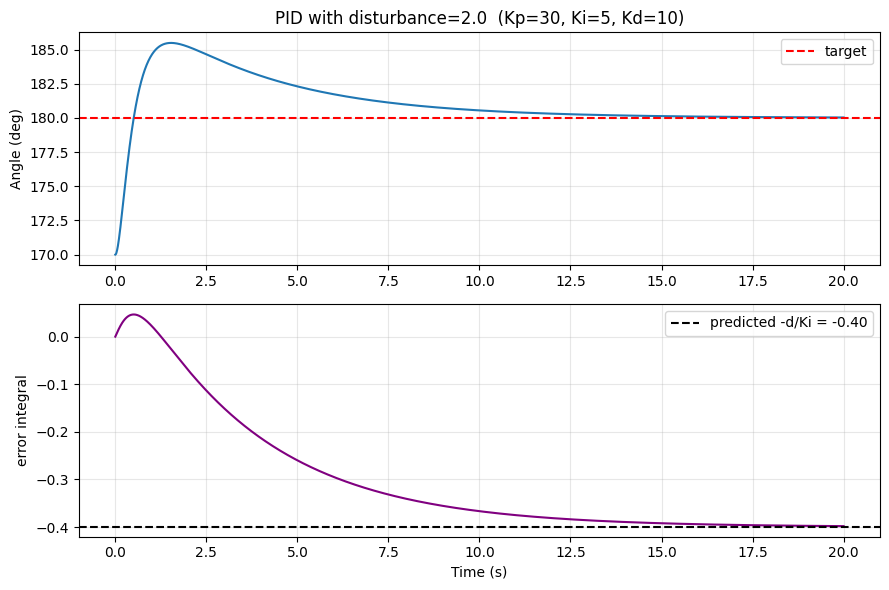

In [14]:
theta_hist, omega_hist, integral_hist = sol.y

print(f"Final theta:    {np.degrees(theta_hist[-1]):.3f} deg  (PD-only gave 185.671)")
print(f"Final omega:    {omega_hist[-1]:.6f}")
print(f"Final integral: {integral_hist[-1]:.4f}  (predicted -0.4)")

fig, ax = plt.subplots(2, 1, figsize=(9, 6))
ax[0].plot(sol.t, np.degrees(theta_hist))
ax[0].axhline(180, color='r', linestyle='--', label='target')
ax[0].set_ylabel('Angle (deg)'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title(f'PID with disturbance={disturbance}  (Kp={Kp}, Ki={Ki}, Kd={Kd})')

ax[1].plot(sol.t, integral_hist, color='purple')
ax[1].axhline(-disturbance/Ki, color='k', linestyle='--', label=f'predicted -d/Ki = {-disturbance/Ki:.2f}')
ax[1].set_xlabel('Time (s)'); ax[1].set_ylabel('error integral'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
##Linearisation and Routh stability check
def routh_first_column(Kp, Ki, Kd):
    a2 = Kd             # coefficient of s^2
    a1 = Kp - g / L     # coefficient of s^1
    a0 = Ki             # coefficient of s^0
    s1 = (a2 * a1 - a0) / a2
    return [1.0, a2, s1, a0]


def count_sign_changes(column):
    changes = 0
    for i in range(len(column) - 1):
        if column[i] * column[i + 1] < 0:
            changes += 1
    return changes


for gains in [(30, 10, 10), (10, 10, 5), (100, 150, 20)]:
    col = routh_first_column(*gains)
    n = count_sign_changes(col)
    print(f"{gains}: first column = {np.round(col, 2)}  ->  {n} unstable root(s)")

(30, 10, 10): first column = [ 1.   10.   19.19 10.  ]  ->  0 unstable root(s)
(10, 10, 5): first column = [ 1.    5.   -1.81 10.  ]  ->  2 unstable root(s)
(100, 150, 20): first column = [  1.    20.    82.69 150.  ]  ->  0 unstable root(s)


In [16]:
for Kp, Ki, Kd in [(30, 10, 10), (10, 10, 5)]:
    roots = np.roots([1, Kd, Kp - g / L, Ki])

    A = np.array([[0,           1,   0 ],
                  [g / L - Kp, -Kd,  Ki],
                  [-1,          0,   0 ]])
    eig = np.linalg.eigvals(A)

    print(f"(Kp, Ki, Kd) = ({Kp}, {Ki}, {Kd})")
    print(f"   roots of polynomial : {np.round(np.sort_complex(roots), 3)}")
    print(f"   eigenvalues of A    : {np.round(np.sort_complex(eig), 3)}")
    print(f"   slowest pole {roots.real.max():.3f}  ->  time constant {1 / abs(roots.real.max()):.2f} s")

(Kp, Ki, Kd) = (30, 10, 10)
   roots of polynomial : [-7.479+0.j -1.762+0.j -0.759+0.j]
   eigenvalues of A    : [-7.479+0.j -1.762+0.j -0.759+0.j]
   slowest pole -0.759  ->  time constant 1.32 s
(Kp, Ki, Kd) = (10, 10, 5)
   roots of polynomial : [-5.318+0.j     0.159-1.362j  0.159+1.362j]
   eigenvalues of A    : [-5.318+0.j     0.159-1.362j  0.159+1.362j]
   slowest pole 0.159  ->  time constant 6.29 s


In [17]:
def evaluate_pid(Kp, Ki, Kd, target=np.radians(180), initial=None, disturbance=2.0, t_max=20):

    if initial is None:
        initial = [np.radians(170), 0.0, 0.0]
    t_eval = np.linspace(0, t_max, 2000)

    sol = solve_ivp(pendulum_with_PID_control, (0, t_max), initial, t_eval=t_eval,
                     args=(target, Kp, Ki, Kd, disturbance), rtol=1e-10, atol=1e-12)
    theta, omega, error_integral = sol.y
    theta_deg = np.degrees(theta)

    #overshoot
    overshoot = max(0, theta_deg.max() - 180)

    # settling time
    err = np.abs(theta_deg - 180)
    band = 0.2
    settled_idx = None
    for i in range(len(err)-1, -1, -1):
        if err[i] > band:
            settling_time = sol.t[i + 1] if i + 1 < len(sol.t) else t_max
            break

    #steady-state error (final error, should be ~0 if I is doing its job)
    steady_state_error = theta_deg[-1] - 180

    #same torque formula as inside pendulum_with_pid_control
    torque = Kp * (target-theta) + Ki * error_integral - Kd * omega
    peak_torque = np.abs(torque).max()

    return overshoot, settling_time, steady_state_error, peak_torque

In [18]:
def cost(Kp, Ki, Kd, w_overshoot=1.0, w_settling=1.0, w_sse=20.0):
    overshoot, settling_time, sse, peak_torque = evaluate_pid(Kp, Ki, Kd)
    return w_overshoot * overshoot + w_settling * settling_time + w_sse * abs(sse)

print(f"cost(30, 5, 10)  = {cost(30, 5, 10):.3f}")
print(f"cost(30, 10, 10) = {cost(30, 10, 10):.3f}")
print(f"cost(10, 10, 5)  = {cost(10, 10, 5):.1f}   <- unstable")

cost(30, 5, 10)  = 19.623
cost(30, 10, 10) = 12.121
cost(10, 10, 5)  = 1363.2   <- unstable


In [19]:
##Grid search
import itertools

def get_cost(r): return r[0]

def run_grid(Kp_values, Ki_values, Kd_values):
    results = []
    for Kp, Ki, Kd in itertools.product(Kp_values, Ki_values, Kd_values):
        overshoot, settling_time, sse, peak_torque = evaluate_pid(Kp, Ki, Kd)
        c = cost(Kp, Ki, Kd)
        results.append((c, Kp, Ki, Kd, peak_torque))
    results.sort(key=get_cost)
    return results

def show_results(results):
    print("Top 5 (lowest cost first):")
    print(f"{len(results)} combinations")
    for c, Kp, Ki, Kd, tau in results[:5]:
        print(f"  cost={c:7.3f}  Kp={Kp:5.1f}  Ki={Ki:5.1f}  Kd={Kd:5.1f}  peak torque={tau:5.1f}")
    print("Worst 3:")
    for c, Kp, Ki, Kd, tau in results[-3:]:
        print(f"  cost={c:7.3f}  Kp={Kp:5.1f}  Ki={Ki:5.1f}  Kd={Kd:5.1f}  peak torque={tau:5.1f}")

results_1 = run_grid([10, 30, 60, 100], [0, 2, 5, 10], [2, 5, 10, 20])
show_results(results_1)



Top 5 (lowest cost first):
64 combinations
  cost= 12.121  Kp= 30.0  Ki= 10.0  Kd= 10.0  peak torque=  5.2
  cost= 14.142  Kp= 30.0  Ki= 10.0  Kd= 20.0  peak torque=  5.2
  cost= 15.081  Kp= 30.0  Ki= 10.0  Kd=  5.0  peak torque=  5.2
  cost= 16.917  Kp= 60.0  Ki= 10.0  Kd= 20.0  peak torque= 10.5
  cost= 16.966  Kp= 60.0  Ki= 10.0  Kd= 10.0  peak torque= 10.5
Worst 3:
  cost=1363.201  Kp= 10.0  Ki= 10.0  Kd=  5.0  peak torque= 14.2
  cost=1680.738  Kp= 10.0  Ki=  5.0  Kd=  2.0  peak torque= 16.4
  cost=2432.469  Kp= 10.0  Ki= 10.0  Kd=  2.0  peak torque= 24.0


In [20]:
results_2 = run_grid([10, 30, 60, 100],
                     [0, 20, 40, 60, 80, 100, 150],
                     [2, 5, 10, 20])
show_results(results_2)

Top 5 (lowest cost first):
112 combinations
  cost=  4.762  Kp=100.0  Ki=150.0  Kd= 20.0  peak torque= 17.5
  cost=  5.013  Kp=100.0  Ki=100.0  Kd= 20.0  peak torque= 17.5
  cost=  5.331  Kp=100.0  Ki= 80.0  Kd= 20.0  peak torque= 17.5
  cost=  5.937  Kp=100.0  Ki= 60.0  Kd= 20.0  peak torque= 17.5
  cost=  6.188  Kp= 60.0  Ki= 60.0  Kd= 20.0  peak torque= 10.5
Worst 3:
  cost=958683423097.827  Kp= 10.0  Ki= 80.0  Kd=  2.0  peak torque=12688194243.0
  cost=15364326842165.158  Kp= 10.0  Ki=100.0  Kd=  2.0  peak torque=896359915140.3
  cost=89285586191034400.000  Kp= 10.0  Ki=150.0  Kd=  2.0  peak torque=1445248169413980.0


           gains |   cost | overshoot | settling | peak torque
  (100, 150, 20) |  4.762 |    3.02 deg |   1.74 s |        17.5
(1000, 500, 100) |  2.940 |    0.51 deg |   2.43 s |       174.5


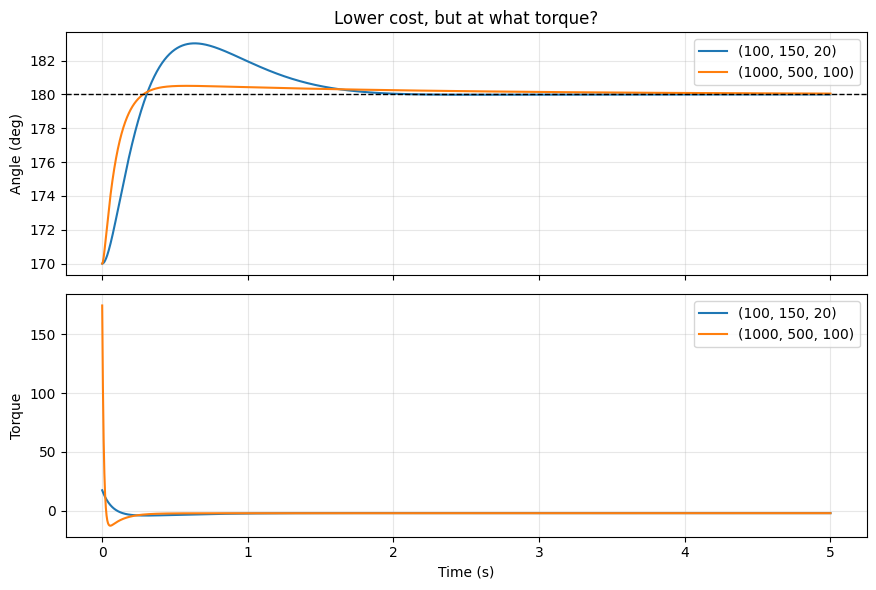

In [24]:
# Compare my best grid result with a much more aggressive set of gains
gain_sets = [(100, 150, 20), (1000, 500, 100)]

print(f"{'gains':>16} | {'cost':>6} | {'overshoot':>9} | {'settling':>8} | {'peak torque':>11}")
for Kp, Ki, Kd in gain_sets:
    overshoot, settling_time, sse, peak_torque = evaluate_pid(Kp, Ki, Kd)
    c = overshoot + settling_time + 20 * abs(sse)      # same weights as cost()
    print(f"{str((Kp, Ki, Kd)):>16} | {c:6.3f} | {overshoot:7.2f} deg | {settling_time:6.2f} s | {peak_torque:11.1f}")

# Plot angle and torque over time for both
t_eval = np.linspace(0, 5, 2000)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

for Kp, Ki, Kd in gain_sets:
    sol = solve_ivp(pendulum_with_PID_control, (0, 5), [np.radians(170), 0.0, 0.0],
                    t_eval=t_eval, args=(target, Kp, Ki, Kd, 2.0), rtol=1e-10, atol=1e-12)
    theta, omega, error_integral = sol.y
    torque = Kp * (target - theta) + Ki * error_integral - Kd * omega   # same formula as the controller

    ax[0].plot(sol.t, np.degrees(theta), label=f'{(Kp, Ki, Kd)}')
    ax[1].plot(sol.t, torque, label=f'{(Kp, Ki, Kd)}')

ax[0].axhline(180, color='k', linestyle='--', linewidth=1)
ax[0].set_ylabel('Angle (deg)'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title('Lower cost, but at what torque?')
ax[1].set_xlabel('Time (s)'); ax[1].set_ylabel('Torque'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Why is **Ki = 150 **fine here when Ki_crit = 201.9 at (Kp=30, Kd=10)? The limit Ki < Kd·(Kp − g/L) depends on the other two gains. At Kp = 100, Kd = 20 it is 20 × 90.19 ≈ 1804, so Ki = 150 is far from the boundary.

The worst three costs are 10¹²–10¹⁷: Kp = 10, Kd = 2 breaks the Routh condition and the oscillation grows exponentially.

In [21]:
def routh_is_stable(Kp, Ki, Kd):
    return Kd > 0 and Kp > g / L and Ki >= 0 and Ki < Kd * (Kp - g / L)


def classify(Kp, Ki, Kd, t_max=20):
    t_eval = np.linspace(0, t_max, 2000)
    sol = solve_ivp(pendulum_with_PID_control, (0, t_max), [np.radians(170), 0.0, 0.0],
                    t_eval=t_eval, args=(target, Kp, Ki, Kd, 2.0), rtol=1e-10, atol=1e-12)
    theta_deg = np.degrees(sol.y[0])
    last_second = theta_deg[-100:]      # last 100 of 2000 points = last 1 s
    if last_second.max() - last_second.min() < 0.2:
        return 'settled'
    err = np.abs(theta_deg - 180)
    if err[-1] > 10:
        return 'grew'
    return 'undecided'


agree = 0
mismatches = []
for c, Kp, Ki, Kd, tau in results_2:
    routh = routh_is_stable(Kp, Ki, Kd)
    sim = classify(Kp, Ki, Kd)
    if (routh and sim == 'settled') or (not routh and sim == 'grew'):
        agree += 1
    else:
        if Ki == 0:     # no integral: the s^0 coefficient is 0, so drop it (PD is 2nd order)
            slowest = np.roots([1, Kd, Kp - g / L]).real.max()
        else:
            slowest = np.roots([1, Kd, Kp - g / L, Ki]).real.max()
        mismatches.append((Kp, Ki, Kd, routh, sim, slowest))

print(f"Clear agreement on {agree} / {len(results_2)} combinations\n")
print("The rest:")
for Kp, Ki, Kd, routh, sim, slowest in mismatches:
    print(f"  ({Kp:3d}, {Ki:3d}, {Kd:2d})  Routh stable: {str(routh):5s}  sim: {sim:9s}  slowest pole real part: {slowest:+.3f}")

Clear agreement on 104 / 112 combinations

The rest:
  ( 30, 150, 10)  Routh stable: True   sim: undecided  slowest pole real part: -0.234
  ( 60,  80,  2)  Routh stable: True   sim: undecided  slowest pole real part: -0.193
  (100, 150,  2)  Routh stable: True   sim: undecided  slowest pole real part: -0.163
  ( 10,  20, 20)  Routh stable: False  sim: undecided  slowest pole real part: +0.020
  ( 30, 100,  5)  Routh stable: True   sim: undecided  slowest pole real part: -0.011
  ( 30,  40,  2)  Routh stable: True   sim: undecided  slowest pole real part: -0.008
  ( 60, 100,  2)  Routh stable: True   sim: grew       slowest pole real part: -0.004
  ( 10,   0, 20)  Routh stable: True   sim: grew       slowest pole real part: -0.010


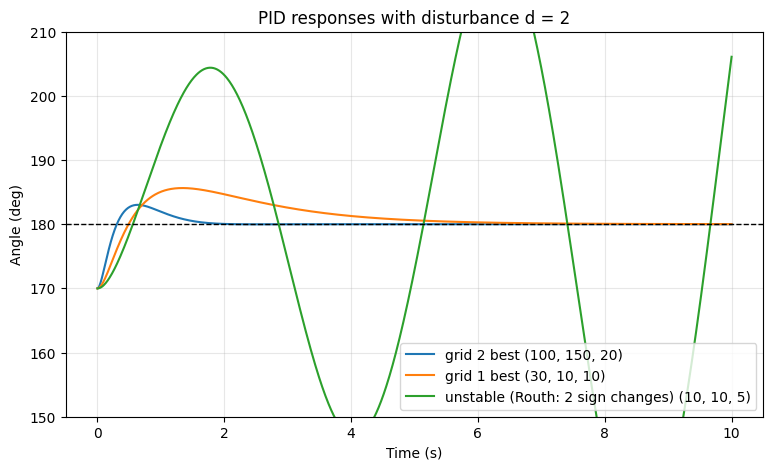

In [22]:
## Best vs first-grid best vs unstable
def simulate_theta(Kp, Ki, Kd, t_max=10):
    t_eval = np.linspace(0, t_max, 1000)
    sol = solve_ivp(pendulum_with_PID_control, (0, t_max), [np.radians(170), 0.0, 0.0],
                    t_eval=t_eval, args=(target, Kp, Ki, Kd, 2.0), rtol=1e-10, atol=1e-12)
    return sol.t, np.degrees(sol.y[0])


plt.figure(figsize=(9, 5))
for gains, label in [((100, 150, 20), 'grid 2 best'),
                     ((30, 10, 10),   'grid 1 best'),
                     ((10, 10, 5),    'unstable (Routh: 2 sign changes)')]:
    t, th = simulate_theta(*gains)
    plt.plot(t, th, label=f'{label} {gains}')

plt.axhline(180, color='k', linestyle='--', linewidth=1)
plt.ylim(150, 210)
plt.xlabel('Time (s)'); plt.ylabel('Angle (deg)')
plt.title('PID responses with disturbance d = 2')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

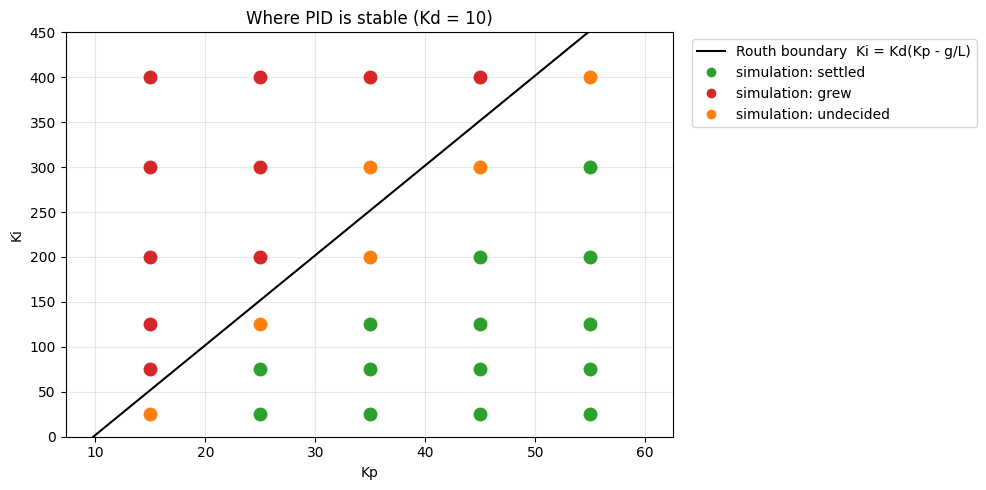

In [23]:
##Stability map (Kd = 10)
Kd_map = 10
Kp_line = np.linspace(g / L, 60, 100)
colours = {'settled': 'tab:green', 'grew': 'tab:red', 'undecided': 'tab:orange'}

plt.figure(figsize=(10, 5))
plt.plot(Kp_line, Kd_map * (Kp_line - g / L), 'k-', label='Routh boundary  Ki = Kd(Kp - g/L)')

for Kp in [15, 25, 35, 45, 55]:
    for Ki in [25, 75, 125, 200, 300, 400]:
        plt.plot(Kp, Ki, 'o', markersize=9, color=colours[classify(Kp, Ki, Kd_map)])

for name, colour in colours.items():
    plt.plot([], [], 'o', color=colour, label=f'simulation: {name}')
plt.xlabel('Kp'); plt.ylabel('Ki')
plt.ylim(0, 450)
plt.title(f'Where PID is stable (Kd = {Kd_map})')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))   # legend outside the plot
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**limitations**

P gives a spring, D gives a brake, I gives memory. P alone can't settle; D removes energy; I removes the steady-state error from a constant disturbance.

Gravity is a negative spring at the top. It's why Kp must exceed g/L, and why my first steady-state prediction (−d/Kp) was wrong.

Routh predicts stability before simulating. Where they seemed to disagree, the simulation was just too short to see a very slow pole, or the pendulum had been pushed outside the range where the linear model holds.

The gains interact. The allowed Ki depends on Kp and Kd, so tuning one gain at a time is misleading.

The best gains are still on the grid edge (Kp = 100, Kd = 20). Bigger gains keep lowering the cost because the cost has no penalty on torque: the peak torque grows with Kp. A real motor has a limit.

Next: add a torque term or saturation to the cost. Choosing the trade-off between error and effort is exactly what LQR's Q and R do.